# Atividade 4: Ensembles

**Dataset escolhido:** [Obesity Levels](https://www.kaggle.com/datasets/fatemehmehrparvar/obesity-levels) (usado no notebook [Obesity Levels Life Style](https://www.kaggle.com/code/mpwolke/obesity-levels-life-style))

Estimativa do nível de obesidade (7 classes) a partir de hábitos alimentares e condição física de pessoas do México, Peru e Colômbia (UCI).

**Grupo**

| Nome | RA |
|-|-|
|Carlos Eduardo Hayashi|10419790|
|Edson Luiz Cardoso Ohira|10419663|
|Thomaz de Souza Scopel|10417183|
|Vitor Tibães Santos|10418976|

In [1]:
!pip install pandas matplotlib seaborn scikit-learn xgboost kagglehub[pandas-datasets]

## 1. Carregamento e preparação dos dados

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from kagglehub import KaggleDatasetAdapter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
SEED = 42

# Carrega o dataset direto do Kaggle (dataset público, não precisa de token)
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "fatemehmehrparvar/obesity-levels",
    "ObesityDataSet_raw_and_data_sinthetic.csv",
)
print(df.shape)
display(df.head())

/usr/local/python/3.14.2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(2111, 17)


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
print(f"Valores ausentes: {df.isnull().sum().sum()}")
print(f"Duplicatas exatas: {df.duplicated().sum()}")
display(df['NObeyesdad'].value_counts())

Valores ausentes: 0
Duplicatas exatas: 24


NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

O dataset não tem valores ausentes e as 7 classes estão bem balanceadas (272 a 351 exemplos), então **acurácia** é uma métrica adequada.
Removemos as 24 duplicatas para evitar que a mesma linha caia no treino e no teste ao mesmo tempo.

Como modelos de árvore não dependem de escala nem de distância, basta transformar as colunas categóricas em códigos inteiros.
As que têm ordem natural (`CAEC`, `CALC`: no < Sometimes < Frequently < Always) recebem códigos ordenados.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)

ordem_freq = {'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3}
binarias = {'yes': 1, 'no': 0}

X = df.drop(columns='NObeyesdad').copy()
X['Gender'] = (X['Gender'] == 'Male').astype(int)
for col in ['FAVC', 'SCC', 'SMOKE', 'family_history_with_overweight']:
    X[col] = X[col].map(binarias)
for col in ['CAEC', 'CALC']:
    X[col] = X[col].map(ordem_freq)
X['MTRANS'] = X['MTRANS'].astype('category').cat.codes

le = LabelEncoder()
y = le.fit_transform(df['NObeyesdad'])
classes = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")

Treino: (1669, 16) | Teste: (418, 16)


## 2. Árvore de decisão sem limite de profundidade

In [5]:
arvore = DecisionTreeClassifier(max_depth=None, random_state=SEED)
arvore.fit(X_train, y_train)

acc_arvore_treino = accuracy_score(y_train, arvore.predict(X_train))
acc_arvore_teste = accuracy_score(y_test, arvore.predict(X_test))
print(f"Profundidade atingida: {arvore.get_depth()} | Folhas: {arvore.get_n_leaves()}")
print(f"Acerto no treino: {acc_arvore_treino:.4f}")
print(f"Acerto no teste:  {acc_arvore_teste:.4f}")

Profundidade atingida: 16 | Folhas: 115
Acerto no treino: 1.0000
Acerto no teste:  0.9354


Sem limite de profundidade, a árvore cresce até decorar o treino (100% de acerto). A diferença para o teste é o sinal de **overfitting** / alta variância de uma árvore única.

## 3. Random Forest com 10, 100 e 300 árvores

,n_arvores,acerto_treino,acerto_teste
0,10,0.998203,0.925837
1,100,1.000000,0.952153
2,300,1.000000,0.954545


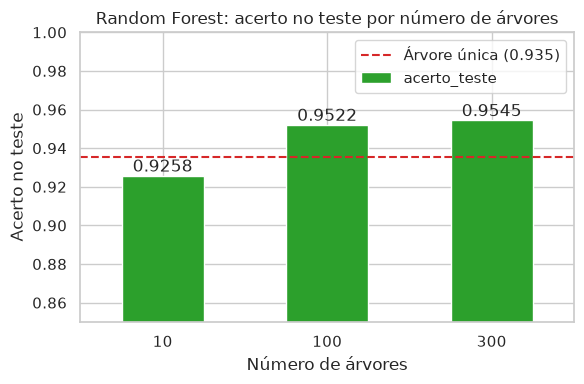

In [6]:
resultados_rf = []
modelos_rf = {}
for n in [10, 100, 300]:
    rf = RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1)
    rf.fit(X_train, y_train)
    modelos_rf[n] = rf
    resultados_rf.append({
        'n_arvores': n,
        'acerto_treino': accuracy_score(y_train, rf.predict(X_train)),
        'acerto_teste': accuracy_score(y_test, rf.predict(X_test)),
    })

df_rf = pd.DataFrame(resultados_rf)
display(df_rf)

ax = df_rf.plot(x='n_arvores', y='acerto_teste', kind='bar', legend=False, color='tab:green', figsize=(6, 4))
ax.axhline(acc_arvore_teste, color='tab:red', ls='--', label=f'Árvore única ({acc_arvore_teste:.3f})')
ax.set_ylim(0.85, 1.0)
ax.set_xlabel('Número de árvores'); ax.set_ylabel('Acerto no teste')
ax.set_title('Random Forest: acerto no teste por número de árvores')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
ax.legend(); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 4. XGBoost: acerto no treino e no teste a cada rodada

In [7]:
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    eval_metric='merror',   # taxa de erro multiclasse -> acerto = 1 - merror
    random_state=SEED,
)
xgb.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=50)

hist = xgb.evals_result()
acc_xgb_treino_rodada = 1 - np.array(hist['validation_0']['merror'])
acc_xgb_teste_rodada = 1 - np.array(hist['validation_1']['merror'])

melhor_rodada = int(np.argmax(acc_xgb_teste_rodada)) + 1
print(f"\nAcerto final -> treino: {acc_xgb_treino_rodada[-1]:.4f} | teste: {acc_xgb_teste_rodada[-1]:.4f}")
print(f"Melhor acerto no teste: {acc_xgb_teste_rodada.max():.4f} na rodada {melhor_rodada}")
print(f"Treino chega a 100% na rodada {int(np.argmax(acc_xgb_treino_rodada == 1)) + 1}")

[0]	validation_0-merror:0.14020	validation_1-merror:0.18660


[50]	validation_0-merror:0.00120	validation_1-merror:0.03828


[100]	validation_0-merror:0.00000	validation_1-merror:0.03349


[150]	validation_0-merror:0.00000	validation_1-merror:0.03110


[200]	validation_0-merror:0.00000	validation_1-merror:0.03110


[250]	validation_0-merror:0.00000	validation_1-merror:0.02632


[299]	validation_0-merror:0.00000	validation_1-merror:0.02871



Acerto final -> treino: 1.0000 | teste: 0.9713
Melhor acerto no teste: 0.9737 na rodada 157
Treino chega a 100% na rodada 55


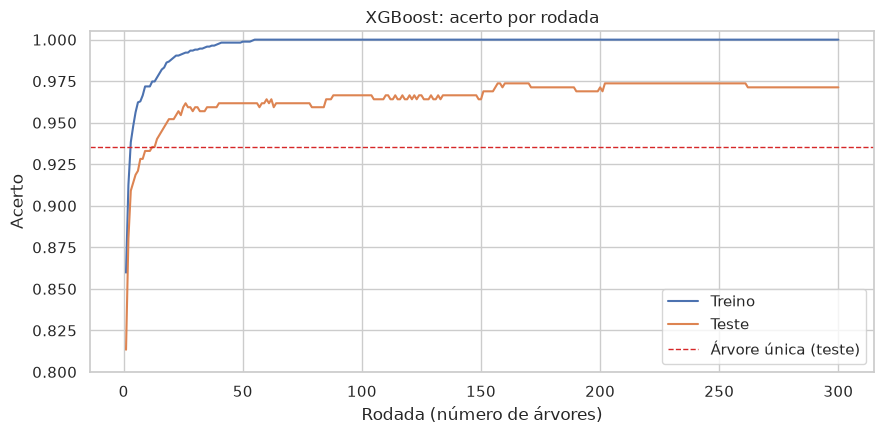

In [8]:
rodadas = np.arange(1, len(acc_xgb_treino_rodada) + 1)
plt.figure(figsize=(9, 4.5))
plt.plot(rodadas, acc_xgb_treino_rodada, label='Treino')
plt.plot(rodadas, acc_xgb_teste_rodada, label='Teste')
plt.axhline(acc_arvore_teste, color='tab:red', ls='--', lw=1, label='Árvore única (teste)')
plt.xlabel('Rodada (número de árvores)'); plt.ylabel('Acerto')
plt.title('XGBoost: acerto por rodada')
plt.ylim(0.8, 1.005); plt.legend(); plt.tight_layout(); plt.show()

Nas primeiras rodadas o acerto sobe rápido nos dois conjuntos. Depois o treino chega a 100% e o teste para de melhorar (fica num platô), então rodadas a mais não trazem ganho.
Como cada nova árvore corrige os resíduos das anteriores com `learning_rate=0.1`, o teste não despenca; ele só estabiliza.

## 5. Comparação e matriz de confusão do melhor modelo

In [9]:
comparacao = pd.DataFrame([
    {'modelo': 'Árvore de decisão', 'acerto_treino': acc_arvore_treino, 'acerto_teste': acc_arvore_teste},
    *[{'modelo': f'Random Forest ({r["n_arvores"]})', 'acerto_treino': r['acerto_treino'], 'acerto_teste': r['acerto_teste']} for r in resultados_rf],
    {'modelo': 'XGBoost (300)', 'acerto_treino': acc_xgb_treino_rodada[-1], 'acerto_teste': acc_xgb_teste_rodada[-1]},
]).sort_values('acerto_teste', ascending=False).reset_index(drop=True)
display(comparacao)

modelos = {'Árvore de decisão': arvore, 'XGBoost (300)': xgb,
           **{f'Random Forest ({n})': m for n, m in modelos_rf.items()}}
nome_melhor = comparacao.loc[0, 'modelo']
melhor = modelos[nome_melhor]
print(f"Melhor modelo no teste: {nome_melhor}")

,modelo,acerto_treino,acerto_teste
0,XGBoost (300),1.000000,0.971292
1,Random Forest (300),1.000000,0.954545
2,Random Forest (100),1.000000,0.952153
3,Árvore de decisão,1.000000,0.935407
4,Random Forest (10),0.998203,0.925837


Melhor modelo no teste: XGBoost (300)


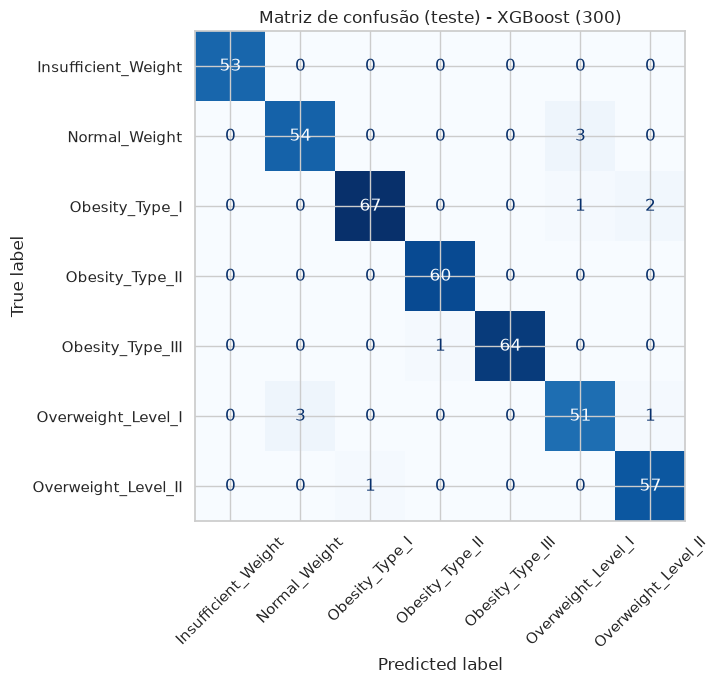

Par com mais confusão: Normal_Weight <-> Overweight_Level_I
  Normal_Weight previsto como Overweight_Level_I: 3
  Overweight_Level_I previsto como Normal_Weight: 3
  Total de erros entre o par: 6 de 12 erros no teste


In [10]:
y_pred = melhor.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title(f'Matriz de confusão (teste) - {nome_melhor}')
plt.tight_layout(); plt.show()

# Par de classes com mais confusão: soma os erros nos dois sentidos (i->j e j->i)
erros = cm.copy()
np.fill_diagonal(erros, 0)
erros_par = erros + erros.T
i, j = np.unravel_index(np.argmax(np.triu(erros_par)), erros_par.shape)
print(f"Par com mais confusão: {classes[i]} <-> {classes[j]}")
print(f"  {classes[i]} previsto como {classes[j]}: {cm[i, j]}")
print(f"  {classes[j]} previsto como {classes[i]}: {cm[j, i]}")
print(f"  Total de erros entre o par: {erros_par[i, j]} de {erros.sum()} erros no teste")

## 6. Importância por permutação

A [importância por permutação](https://scikit-learn.org/stable/modules/permutation_importance.html) embaralha uma coluna por vez no conjunto de **teste** e mede quanto o acerto cai.
Quanto maior a queda, mais o modelo depende daquele atributo. Usamos o teste (e não o treino) para medir o que realmente ajuda a generalizar.

,atributo,queda_media_acerto,desvio
0,Weight,0.743062,0.017041
1,Height,0.254904,0.011756
2,Gender,0.134211,0.011295
3,FAVC,0.014713,0.001564
4,Age,0.010646,0.005321
5,NCP,0.010167,0.004403
6,TUE,0.008493,0.004107
7,FCVC,0.006220,0.003500
8,CH2O,0.006220,0.002554
9,CALC,0.003828,0.003500


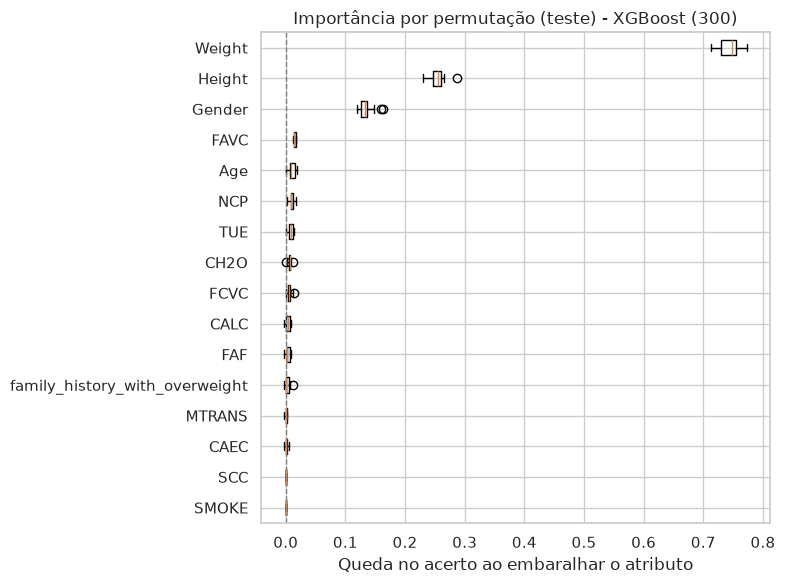

In [11]:
perm = permutation_importance(melhor, X_test, y_test, n_repeats=20, random_state=SEED, scoring='accuracy', n_jobs=-1)

imp = pd.DataFrame({
    'atributo': X.columns,
    'queda_media_acerto': perm.importances_mean,
    'desvio': perm.importances_std,
}).sort_values('queda_media_acerto', ascending=False).reset_index(drop=True)
display(imp)

ordem = perm.importances_mean.argsort()
plt.figure(figsize=(8, 6))
plt.boxplot(perm.importances[ordem].T, orientation='horizontal', tick_labels=X.columns[ordem])
plt.axvline(0, color='gray', ls='--', lw=1)
plt.xlabel('Queda no acerto ao embaralhar o atributo')
plt.title(f'Importância por permutação (teste) - {nome_melhor}')
plt.tight_layout(); plt.show()

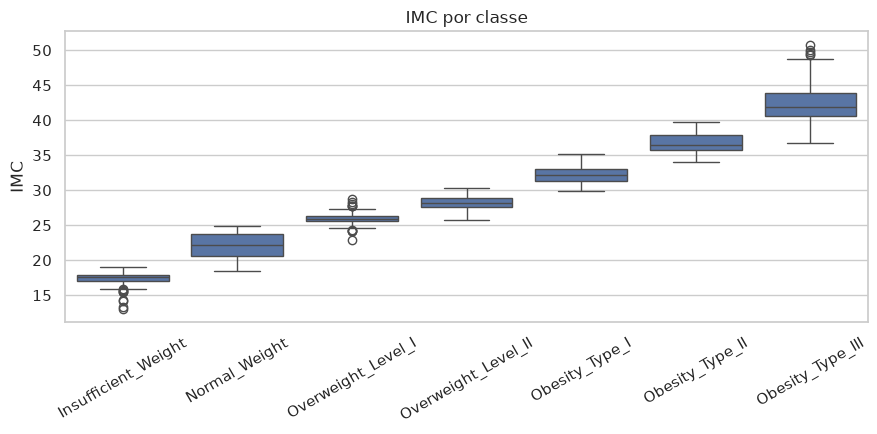

In [12]:
# Por que Weight e Height dominam? O rótulo foi criado a partir do IMC = peso / altura²
imc = df['Weight'] / df['Height'] ** 2
ordem_classes = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
                 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
plt.figure(figsize=(9, 4.5))
sns.boxplot(x=df['NObeyesdad'], y=imc, order=ordem_classes)
plt.xticks(rotation=30); plt.xlabel(''); plt.ylabel('IMC'); plt.title('IMC por classe')
plt.tight_layout(); plt.show()

In [13]:
# Sem Weight e Height, o que sobra são só hábitos/estilo de vida
X_hab_train = X_train.drop(columns=['Weight', 'Height'])
X_hab_test = X_test.drop(columns=['Weight', 'Height'])

arv_hab = DecisionTreeClassifier(random_state=SEED).fit(X_hab_train, y_train)
rf_hab = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_hab_train, y_train)
print(f"Sem peso/altura -> Árvore: {accuracy_score(y_test, arv_hab.predict(X_hab_test)):.4f} | "
      f"RF(300): {accuracy_score(y_test, rf_hab.predict(X_hab_test)):.4f}")

Sem peso/altura -> Árvore: 0.7632 | RF(300): 0.8589


## 7. Conclusão

In [14]:
ganho = comparacao.loc[0, 'acerto_teste'] - acc_arvore_teste
erros_arvore = 1 - acc_arvore_teste
erros_melhor = 1 - comparacao.loc[0, 'acerto_teste']
print(f"Árvore única (teste): {acc_arvore_teste:.4f}")
print(f"{nome_melhor} (teste): {comparacao.loc[0, 'acerto_teste']:.4f}")
print(f"Ganho absoluto: {ganho * 100:+.2f} pontos percentuais")
print(f"Redução da taxa de erro: {(1 - erros_melhor / erros_arvore) * 100:.1f}%")

Árvore única (teste): 0.9354
XGBoost (300) (teste): 0.9713
Ganho absoluto: +3.59 pontos percentuais
Redução da taxa de erro: 55.6%


### Quanto o ensemble ganhou sobre a árvore sozinha?

| Modelo | Acerto treino | Acerto teste |
|-|-|-|
| Árvore de decisão (sem limite) | 100% | 93,54% |
| Random Forest (10) | 99,82% | 92,58% |
| Random Forest (100) | 100% | 95,22% |
| Random Forest (300) | 100% | 95,45% |
| **XGBoost (300 rodadas)** | **100%** | **97,13%** |

- O **XGBoost** foi o melhor modelo: **+3,6 pontos percentuais** sobre a árvore única (93,5% → 97,1%). Parece pouco, mas a taxa de erro caiu de 6,5% para 2,9%, ou seja, **~56% menos erros** (de 27 para 12 erros em 418 exemplos de teste).
- A **Random Forest** ganhou cerca de **+2 p.p.** com 100–300 árvores. Com só **10 árvores ela foi pior que a árvore única**: poucas árvores não bastam para a média reduzir a variância. De 100 para 300 árvores o ganho é quase nulo (+0,2 p.p.), então o benefício satura.
- No XGBoost, o treino chega a 100% na rodada 55 e o teste estabiliza em ~97% depois de ~150 rodadas. O melhor ponto (97,37%, rodada 157) não está longe do final.
- O par de classes mais confundido foi **Normal_Weight ↔ Overweight_Level_I** (6 dos 12 erros). São classes vizinhas na escala de IMC, e os erros ficam nas pessoas perto do limite de 25.
- Pela importância por permutação, o atributo que **mais pesou foi `Weight` (peso)**: embaralhá-lo derruba o acerto em ~74 p.p. Depois vêm `Height` (~25 p.p.) e `Gender` (~13 p.p.). Os hábitos de vida quase não importam para o modelo.

### Limitações vistas em aula que se aplicam ao nosso resultado

1. **Overfitting / alta variância da árvore única.** A árvore sem limite de profundidade decorou o treino (100%, 115 folhas). Os ensembles atacam justamente isso: a Random Forest faz a média de árvores descorrelacionadas (bagging), e o boosting corrige os erros aos poucos. Todos os modelos ainda têm 100% no treino, então a diferença treino × teste não some, só diminui.
2. **Perda de interpretabilidade.** A árvore única pode ser lida como regras "se… então". A Random Forest com 300 árvores e o XGBoost são caixas-pretas. Por isso precisamos da importância por permutação para entender o que o modelo usa, e ela só mostra a importância *global*, não o porquê de cada previsão.
3. **Custo computacional e retorno decrescente.** Treinar 300 árvores custa ~300× mais que uma, para ganhar poucos pontos. Na RF o ganho satura depois de ~100 árvores, e no XGBoost depois de ~150 rodadas.
4. **O ensemble não corrige problemas dos dados ("garbage in, garbage out").** É a limitação mais importante aqui:
   - **Vazamento do alvo:** a classe foi rotulada a partir do **IMC = peso / altura²**. Por isso `Weight` e `Height` dominam a importância, e o modelo basicamente reaprende a fórmula do IMC em vez de estimar obesidade a partir de *hábitos*. Sem peso e altura, o acerto cai para ~76% (árvore) e ~86% (RF). Esse é o desempenho real se o objetivo for prever pelo estilo de vida, e é onde o ensemble mostra o maior ganho (+10 p.p.).
   - **Dados sintéticos:** segundo a documentação da UCI, ~77% das linhas foram geradas por **SMOTE** (dá para ver pelas idades e frequências fracionárias). Isso cria padrões artificiais: `Obesity_Type_II` tem 295 homens e 2 mulheres, e `Obesity_Type_III` tem 323 mulheres e 1 homem. Por isso `Gender` aparece como o 3º atributo mais importante. Além disso, linhas sintéticas parecidas podem ficar no treino e no teste ao mesmo tempo, o que **infla o acerto no teste**. Os ~97% provavelmente são otimistas em relação a dados reais.
   - **Pouca amostra:** o teste tem 418 exemplos, então 1 erro equivale a 0,24 p.p. Diferenças pequenas, como RF(100) contra RF(300), estão dentro do ruído. Uma validação cruzada daria uma estimativa mais confiável.